# Análisis de Lesionados en Accidentes de Tránsito — Santiago de Cali (2016–2025)

**Proyecto de Reinforcement Learning: agente Q-Learning para el control de la siniestralidad vial**

| Campo | Detalle |
|---|---|
| **Autores** | Cristian Alejandro Perdomo · Edixon Rubiano |
| **Institución** | Universidad de Cundinamarca (UDEC) |
| **Repositorio** | <https://github.com/CAlejandroPerdomo/UDEC-Reinforcement-Learning> |
| Fuente | `lesionados-en-santiago-de-cali-del-2016-2025.csv` (dataset ya descargado) |
| Alcance | Lesionados en accidentes de tránsito, Cali (2016–2025) |
| Entorno | Python 3.14 · pandas 3.x · matplotlib 3.x · numpy 2.x |
| Objetivo | EDA y limpieza → formulación del MDP → Q-Learning → evaluación y sensibilidad |

> El presente notebook integra las cuatro etapas del proyecto: (1) carga, limpieza y análisis
> exploratorio; (2) diseño del entorno y del agente; (3) evaluación comparativa y análisis de
> sensibilidad; y (4) interpretación general, conclusiones y limitaciones.


## 0. Configuración del entorno

Importación de librerías y definición de constantes de rutas. Se usa `matplotlib` con backend estático (`Agg`) para garantizar generación de figuras sin pantalla; las gráficas se guardan en `graficas/` y se muestran inline vía `plt.show()` cuando el kernel lo soporta.

In [1]:
# --- Librerías ---
import os
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Configuración global de visualización
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Constantes de ruta ---
RUTA_RAW = "lesionados-en-santiago-de-cali-del-2016-2025.csv"
RUTA_SALIDA = "dataset_preparado.csv"
DIR_GRAFICAS = "graficas"
os.makedirs(DIR_GRAFICAS, exist_ok=True)

print("Versiones:")
print("  pandas   ", pd.__version__)
print("  numpy    ", np.__version__)
print("  matplotlib", matplotlib.__version__)


Versiones:
  pandas    3.0.6
  numpy     2.5.4
  matplotlib 3.11.2


## 1. Carga del dataset

Se lee el archivo crudo. Dos decisiones de bajo nivel son relevantes:

- **Encoding:** el archivo está en **Latin-1 (CP1252)**; valores como `Dirección` o `CLÍNICA` llegan codificados en bytes de 8 bits. Se usa `encoding="latin1"`.
- **Delimitador:** `;` (punto y coma), con saltos de línea CRLF.

Se inspeccionan dimensiones y estructura general.

In [2]:
df_raw = pd.read_csv(RUTA_RAW, sep=";", encoding="latin1")

print(f"Forma original: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print("\nColumnas originales:")
for i, c in enumerate(df_raw.columns, 1):
    print(f"  {i:2d}. {c!r}")


Forma original: 51,236 filas × 10 columnas

Columnas originales:
   1. 'Fecha'
   2. 'Hora'
   3. 'Tipo_Confirmado'
   4. 'Placa Agente de Transito'
   5. 'Dirección_Reporte'
   6. 'Tipo_Confirmado.1'
   7. 'Automovil'
   8. 'Moto'
   9. 'Ciclista'
  10. 'Peaton'


Vista preliminar de las primeras filas para evidenciar el marcador `.` como valor ausente y la columna duplicada `Tipo_Confirmado`.

In [3]:
df_raw.head(8)

,Fecha,Hora,Tipo_Confirmado,Placa Agente de Transito,Dirección_Reporte,Tipo_Confirmado.1,Automovil,Moto,Ciclista,Peaton
0,1/01/2016,0:49,Con lesionado,.,Carrera 94 Con Calle 4 C,Por Atropello,.,.,.,.
1,1/01/2016,1:03,Con lesionado,.,Carrera 8 A Con Calle 44,Por Volcamiento,.,.,.,.
2,1/01/2016,1:52,Con lesionado,.,Carrera 23 Con Transversal 25,Choque con Lesionados,.,.,.,.
3,1/01/2016,3:39,Con lesionado,.,CAI COMERCIO,Por Atropello,.,.,.,.
4,1/01/2016,4:03,Con lesionado,.,Carrera 94 Con Calle 4 B,Choque con Lesionados,.,.,.,.
5,1/01/2016,8:01,Con lesionado,.,Calle 25 Con Carrera 68 Y 69,Choque con Lesionados,.,.,.,.
6,1/01/2016,8:54,Con lesionado,.,Calle 25 Con Carrera 50,Choque con Lesionados,.,.,.,.
7,1/01/2016,8:57,Con lesionado,.,Calle 27 Con Carrera 40b,Choque con Lesionados,.,.,.,.


## 2. Inspección de columnas, tipos y valores faltantes

### 2.1 Tipos de dato

Al cargar sin especificar tipos, `pandas` infiere todo como `object` (texto). Esto es un primer indicio de que **no hay inferencia numérica/datetime automática** y de que se requiere conversión explícita.

In [4]:
df_raw.dtypes.to_frame("dtype")

,dtype
Fecha,str
Hora,str
Tipo_Confirmado,str
Placa Agente de Transito,str
Dirección_Reporte,str
Tipo_Confirmado.1,str
Automovil,str
Moto,str
Ciclista,str
Peaton,str


### 2.2 Valores faltantes (NaN reales)

El archivo casi no usa campos vacíos; en su lugar el ausente se codifica con el **carácter `.`** (punto). La cuenta de `NaN` reales es mínima.

In [5]:
print("NaN reales por columna:")
print(df_raw.isna().sum())

NaN reales por columna:
Fecha                       0
Hora                        0
Tipo_Confirmado             0
Placa Agente de Transito    0
Dirección_Reporte           1
Tipo_Confirmado.1           0
Automovil                   0
Moto                        0
Ciclista                    0
Peaton                      0
dtype: int64


### 2.3 Marcador `.` (punto) como ausente

El `.` aparece de forma masiva y se interpreta como **dato ausente**. Se cuantifica su presencia por columna.

In [6]:
conteo_punto = (df_raw == ".").sum()
print("Celdas con '.' por columna:")
display(conteo_punto.to_frame("n_punto"))
print("\nFracción de '.' sobre el total de filas:")
display((conteo_punto / len(df_raw)).round(3).to_frame("frac_punto"))

Celdas con '.' por columna:


,n_punto
Fecha,0
Hora,0
Tipo_Confirmado,0
Placa Agente de Transito,33245
Dirección_Reporte,20509
Tipo_Confirmado.1,10820
Automovil,39298
Moto,38497
Ciclista,50314
Peaton,49298



Fracción de '.' sobre el total de filas:


,frac_punto
Fecha,0.000
Hora,0.000
Tipo_Confirmado,0.000
Placa Agente de Transito,0.649
Dirección_Reporte,0.400
Tipo_Confirmado.1,0.211
Automovil,0.767
Moto,0.751
Ciclista,0.982
Peaton,0.962


## 3. Semántica y valores únicos por columna

Antes de transformar, se documenta el dominio real de cada variable. Esto evita decisiones erróneas de limpieza.

### 3.1 `Tipo_Confirmado` (primera) — constante y redundante

In [7]:
print("Valores únicos de la primera 'Tipo_Confirmado':")
print(df_raw["Tipo_Confirmado"].unique())


Valores únicos de la primera 'Tipo_Confirmado':
<ArrowStringArray>
['Con lesionado']
Length: 1, dtype: str


### 3.2 `Tipo_Confirmado.1` (segunda) — clase real del evento

La segunda columna con este nombre es la que aporta información: describe la **clase/tipo de evento** (choque, atropello, volcamiento, etc.).

In [8]:
print("Distribución de la clase de evento:")
display(df_raw["Tipo_Confirmado.1"].value_counts(dropna=False).to_frame("n"))

Distribución de la clase de evento:


,n
Tipo_Confirmado.1,
Choque con Lesionados,26793
.,10820
CON HERIDOS,6215
Por Atropello,4324
Por Volcamiento,1093
POSITIVO,958
Por Caida de Ocupante,906
NEGATIVO,118
Lesiones (Humano golpea vehiculo estacionado),5


### 3.3 `Placa Agente de Transito` — identificador del agente

In [9]:
display(df_raw["Placa Agente de Transito"].value_counts(dropna=False).head(12).to_frame("n"))

,n
Placa Agente de Transito,
.,33245
530,335
138,335
637,304
305,288
299,275
27,265
455,239
652,234


### 3.4 Flags de víctimas (`Automovil`, `Moto`, `Ciclista`, `Peaton`)

Variables binarias donde `1` indica que hubo al menos una víctima de ese tipo de actor vial, y `.` indica **no registrado**.

In [10]:
flags = ["Automovil", "Moto", "Ciclista", "Peaton"]
for c in flags:
    print(f"{c:10s} ->", df_raw[c].value_counts(dropna=False).to_dict())

Automovil  -> {'.': 39298, '1': 11938}
Moto       -> {'.': 38497, '1': 12739}
Ciclista   -> {'.': 50314, '1': 922}
Peaton     -> {'.': 49298, '1': 1938}


### 3.5 `Dirección_Reporte` — variable geográfica (texto libre)

Ubicación del hecho. Mezcla **intersecciones** (`Calle 70 Con Carrera 8`), **puntos de interés** (clínicas, hospitales, CAI, vías) y presenta **inconsistencias de forma** (mayúsculas/minúsculas y acentos mal codificados).

In [11]:
col_dir = "Dirección_Reporte"
print(f"Valores únicos: {df_raw[col_dir].nunique():,}")
print("\nTop 15 ubicaciones:")
display(df_raw[col_dir].value_counts(dropna=False).head(15).to_frame("n"))

Valores únicos: 16,732

Top 15 ubicaciones:


,n
Dirección_Reporte,
.,20509
CLINICA COLOMBIA,119
CLINICA CRISTO REY,112
Calle 70 Con Carrera 8,78
Calle 5 Con Carrera 80,61
Carrera 23 Con Transversal 25,59
Calle 10 Con Carrera 66,59
Calle 16 Con Carrera 100,59
Calle 10 Con Carrera 39,58


In [12]:
# Patrón inicial de cada dirección para evidenciar heterogeneidad
prefijo = df_raw[col_dir].fillna("<NaN>").str.split(" ").str[0]
display(prefijo.value_counts().head(20).to_frame("n"))

,n
Dirección_Reporte,
.,20509
Calle,13990
Carrera,5818
CALLE,4745
CARRERA,1645
Avenida,1362
CLINICA,575
AVENIDA,397
Transversal,306


### 3.6 `Fecha` y `Hora` — variables temporales (formatos mixtos)

Se detectan **formatos heterogéneos** que requieren tratamiento específico:

- **Fecha:** conviven `dd/mm/yyyy` (mayoría) y `mm/dd/yyyy` (solo 166 filas de septiembre-2025).
- **Hora:** conviven `H:MM`, `HH:MM`, `H:MM:SS`, formato 12h con sufijo `a./p. m.`, fracción de día de Excel y sufijo de zona horaria `-05`.

In [13]:
def primer_componente(cad):
    try:
        return int(cad.split("/")[0])
    except Exception:
        return None

pc = df_raw["Fecha"].astype(str).apply(primer_componente)
print("Filas con primer componente de fecha > 12 (potencial mm/dd):", (pc > 12).sum())

# Detección precisa de mm/dd: mes<=12 y 'día'>12
def es_mmdd(cad):
    try:
        p = cad.split("/")
        return int(p[0]) <= 12 and int(p[1]) > 12
    except Exception:
        return False

mask_mmdd_raw = df_raw["Fecha"].astype(str).apply(es_mmdd)
print("Filas en formato mm/dd/yyyy:", mask_mmdd_raw.sum())
print("\nAños (3er componente) en esas filas:",
      df_raw.loc[mask_mmdd_raw, "Fecha"].str.split("/").str[2].value_counts().to_dict())


Filas con primer componente de fecha > 12 (potencial mm/dd): 30837


Filas en formato mm/dd/yyyy: 166

Años (3er componente) en esas filas: {'2025': 166}


In [14]:
# Formatos de Hora presentes
h_raw = df_raw["Hora"].astype(str)
print("Conteo de ':' por valor de hora:")
display(h_raw.str.count(":").value_counts().sort_index().to_frame("n"))
print("\nPatrón numérico con coma (fracción Excel):", h_raw.str.contains(",", na=False).sum())
print("Patrón numérico con punto (fracción Excel):", h_raw.str.match(r"^[0-9]+[.,][0-9]+$", na=False).sum())
print("Sufijo zona horaria '-05':", h_raw.str.contains(r"-05$", na=False).sum())
print("Sufijo 12h a./p.:", h_raw.str.match(r"\d{1,2}:\d{2}(:\d{2})?\s*[ap]\.", case=False, na=False).sum())


Conteo de ':' por valor de hora:


,n
Hora,
0,101
1,14979
2,36156



Patrón numérico con coma (fracción Excel): 56
Patrón numérico con punto (fracción Excel): 100
Sufijo zona horaria '-05': 257
Sufijo 12h a./p.: 935


## 4. Limpieza y preparación (justificada)

Se aplican, en orden, las siguientes transformaciones. Cada una está respaldada por lo evidenciado en §3.

### 4.1 Renombrado y eliminación de columna redundante

- `Dirección_Reporte` → `Direccion` (sin tilde, para portabilidad).
- `Tipo_Confirmado.1` → `Tipo_Evento` (nombre descriptivo).
- Se **elimina** la primera `Tipo_Confirmado` por ser constante (`Con lesionado`).

In [15]:
df = df_raw.copy()

df = df.rename(columns={
    "Dirección_Reporte": "Direccion",
    "Tipo_Confirmado.1": "Tipo_Evento",
})
df = df.drop(columns=["Tipo_Confirmado"])

print("Columnas tras renombrado:", df.columns.tolist())

Columnas tras renombrado: ['Fecha', 'Hora', 'Placa Agente de Transito', 'Direccion', 'Tipo_Evento', 'Automovil', 'Moto', 'Ciclista', 'Peaton']


### 4.2 Normalización del marcador `.` a `NaN`

Todo `.` pasa a `NaN` (valor ausente real de pandas), lo que habilita `isna()`, `dropna()` y el resto de la maquinaria de datos faltantes.

In [16]:
df = df.replace(".", np.nan)
print("NaN tras reemplazo de '.':")
display(df.isna().sum().to_frame("n_nan"))

NaN tras reemplazo de '.':


,n_nan
Fecha,0
Hora,0
Placa Agente de Transito,33245
Direccion,20510
Tipo_Evento,10820
Automovil,39298
Moto,38497
Ciclista,50314
Peaton,49298


### 4.3 Conversión de `Fecha` (doble formato)

Se parsea primero con `format="%d/%m/%Y"` (formato dominante) y se **corrigen** las 166 filas en `mm/dd/yyyy` reparseándolas con `%m/%d/%Y`, asignando por máscara booleana.

In [17]:
fecha_raw = df["Fecha"].astype(str)

def es_mmdd(cad):
    try:
        p = cad.split("/")
        return int(p[0]) <= 12 and int(p[1]) > 12
    except Exception:
        return False

mask_mmdd = fecha_raw.apply(es_mmdd)
fecha = pd.to_datetime(fecha_raw, format="%d/%m/%Y", errors="coerce")
fecha_mmdd = pd.to_datetime(fecha_raw[mask_mmdd], format="%m/%d/%Y", errors="coerce")
fecha.loc[mask_mmdd] = fecha_mmdd.values

df["Fecha"] = fecha
print("Fechas sin parsear:", fecha.isna().sum())
print("Rango:", fecha.min(), "→", fecha.max())

Fechas sin parsear: 0
Rango: 2016-01-01 00:00:00 → 2025-12-09 00:00:00


### 4.4 Conversión de `Hora` (múltiples formatos)

Se normaliza a hora del día (24h) manejando, en cascada:

1. `H:MM` / `HH:MM`.
2. `H:MM:SS` / `HH:MM:SS`.
3. Formato 12h con sufijo `a.·m.` / `p.·m.` (935 filas).
4. Fracción de día de Excel con coma o punto (379 filas).
5. Sufijo de zona horaria `-05` (279 filas).
6. Dígito basura inicial (22 filas).

In [18]:
def normalizar_12h(cad):
    m = re.match(r"^(\d{1,2}):(\d{1,2})(?::(\d{1,2}))?\s*([ap])\.", cad.strip(), re.IGNORECASE)
    if not m:
        return cad
    hh = int(m.group(1)); mm = int(m.group(2)); ss = m.group(3)
    mer = m.group(4).lower()
    if mer == "p" and hh != 12:
        hh += 12
    if mer == "a" and hh == 12:
        hh = 0
    hh %= 24
    return f"{hh:02d}:{mm:02d}" + (f":{ss}" if ss else "")

def fraccion_a_hora(cad):
    try:
        frac = float(cad.replace(",", "."))
        total_seg = round(frac * 24 * 3600)
        hh = (total_seg // 3600) % 24
        mm = (total_seg % 3600) // 60
        return pd.Timestamp(f"2000-01-01 {hh:02d}:{mm:02d}:00")
    except Exception:
        return pd.NaT

def limpiar_basura(cad):
    m = re.search(r"(\d{1,2}):(\d{1,2})(?::(\d{1,2}))?\s*([ap])?\.", cad.strip(), re.IGNORECASE)
    if not m:
        return cad
    hh = int(m.group(1)); mm = int(m.group(2)); ss = m.group(3)
    mer = (m.group(4) or "").lower()
    if mer == "p" and hh != 12:
        hh += 12
    if mer == "a" and hh == 12:
        hh = 0
    hh %= 24
    return f"{hh:02d}:{mm:02d}" + (f":{ss}" if ss else "")


In [19]:
hora_raw = df["Hora"].astype(str)
hora = pd.to_datetime(hora_raw, format="%H:%M", errors="coerce")

# (a) con segundos
mask_ss = hora_raw.str.count(":") == 2
hora.loc[mask_ss] = pd.to_datetime(hora_raw[mask_ss], format="%H:%M:%S", errors="coerce").values

# (b) 12h a./p.
aun_nan = hora.isna()
mask_12h = aun_nan & hora_raw.str.match(r"\d{1,2}:\d{2}(:\d{2})?\s*[ap]\.", case=False, na=False)
hora.loc[mask_12h] = pd.to_datetime(hora_raw[mask_12h].apply(normalizar_12h), format="%H:%M:%S", errors="coerce").values

# (c) fracción Excel
aun_nan = hora.isna()
mask_num = aun_nan & hora_raw.str.match(r"^[0-9]+[.,][0-9]+$", na=False)
hora.loc[mask_num] = hora_raw[mask_num].apply(fraccion_a_hora).values

# (d) zona horaria -05
aun_nan = hora.isna()
mask_tz = aun_nan & hora_raw.str.match(r"\d{1,2}:\d{2}:\d{2}-05", na=False)
hora.loc[mask_tz] = pd.to_datetime(hora_raw[mask_tz].str.replace(r"-05$", "", regex=True), format="%H:%M:%S", errors="coerce").values

# (e) basura inicial
aun_nan = hora.isna()
hora.loc[aun_nan] = pd.to_datetime(hora_raw[aun_nan].apply(limpiar_basura), format="%H:%M:%S", errors="coerce").values

# Conservar solo la componente horaria (hora:minuto:segundo sin fecha 1900)
df["Hora"] = hora.dt.time
print("Horas sin parsear:", hora.isna().sum())
if hora.isna().any():
    print("Residuos sin parsear:", hora_raw[hora.isna()].unique()[:10])

Horas sin parsear: 1
Residuos sin parsear: <ArrowStringArray>
['0']
Length: 1, dtype: str


### 4.5 Flags de víctimas → 0/1 y total

`Automovil`, `Moto`, `Ciclista`, `Peaton` pasan a enteros binarios (1 = víctima de ese tipo, 0 = no registrado). Se añade `Total_Victimas` como suma, que **no** representa el total real (hay subregistro) sino el número de tipos de actor con flag activo.

In [20]:
flags = ["Automovil", "Moto", "Ciclista", "Peaton"]
for c in flags:
    df[c] = df[c].astype(float).fillna(0).astype(int)

df["Total_Victimas"] = df[flags].sum(axis=1)
print("Suma de flags de víctimas por tipo:")
display(df[flags].sum().to_frame("n_accidentes"))

Suma de flags de víctimas por tipo:


,n_accidentes
Automovil,11938
Moto,12739
Ciclista,922
Peaton,1938


### 4.6 Variables temporales derivadas

In [21]:
df["Año"] = df["Fecha"].dt.year
df["Mes"] = df["Fecha"].dt.month
df["Dia"] = df["Fecha"].dt.day
df["Dia_Semana"] = df["Fecha"].dt.day_name("spanish")
print(df[["Fecha","Año","Mes","Dia","Dia_Semana"]].head())

       Fecha   Año  Mes  Dia Dia_Semana
0 2016-01-01  2016    1    1    Viernes
1 2016-01-01  2016    1    1    Viernes
2 2016-01-01  2016    1    1    Viernes
3 2016-01-01  2016    1    1    Viernes
4 2016-01-01  2016    1    1    Viernes


### 4.7 Duplicados y ordenamiento

In [22]:
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
df = df.sort_values(["Fecha", "Hora"], na_position="last").reset_index(drop=True)
print("Duplicados exactos eliminados:", n_dup)
print("Forma final:", df.shape)

Duplicados exactos eliminados: 3
Forma final: (51233, 14)


### 4.8 Tipos de dato finales

In [23]:
df["Placa Agente de Transito"] = df["Placa Agente de Transito"].astype(str).str.strip()
display(df.dtypes.to_frame("dtype"))
print("\nValores nulos finales:")
display(df.isna().sum().to_frame("n_nan"))

,dtype
Fecha,datetime64[us]
Hora,object
Placa Agente de Transito,str
Direccion,str
Tipo_Evento,str
Automovil,int64
Moto,int64
Ciclista,int64
Peaton,int64
Total_Victimas,int64



Valores nulos finales:


,n_nan
Fecha,0
Hora,1
Placa Agente de Transito,33242
Direccion,20507
Tipo_Evento,10820
Automovil,0
Moto,0
Ciclista,0
Peaton,0
Total_Victimas,0


## 5. Persistencia del dataset preparado

Se guarda en UTF-8 (con BOM) y delimitador `;` para preservar acentos y mantener consistencia con el origen.

In [24]:
df.to_csv(RUTA_SALIDA, sep=";", index=False, encoding="utf-8-sig")
print(f"Guardado en: {RUTA_SALIDA} ({len(df):,} filas × {df.shape[1]} columnas)")

Guardado en: dataset_preparado.csv (51,233 filas × 14 columnas)


## 6. Análisis exploratorio (EDA)

### 6.1 Serie temporal por año

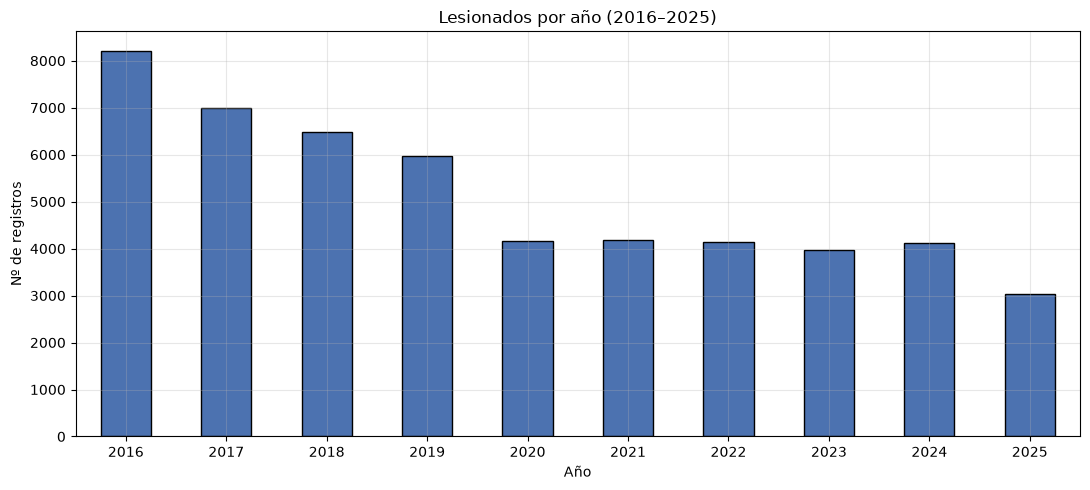

,n
Año,
2016,8215
2017,6985
2018,6473
2019,5973
2020,4167
2021,4175
2022,4131
2023,3963
2024,4126


In [25]:
ser = df["Año"].value_counts().sort_index()
ax = ser.plot(kind="bar", color="#4C72B0", edgecolor="black")
ax.set_title("Lesionados por año (2016–2025)")
ax.set_xlabel("Año"); ax.set_ylabel("Nº de registros")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g1_por_anio.png"), dpi=150)
plt.show()
display(ser.to_frame("n"))

### 6.2 Estacionalidad mensual (promedio por año)

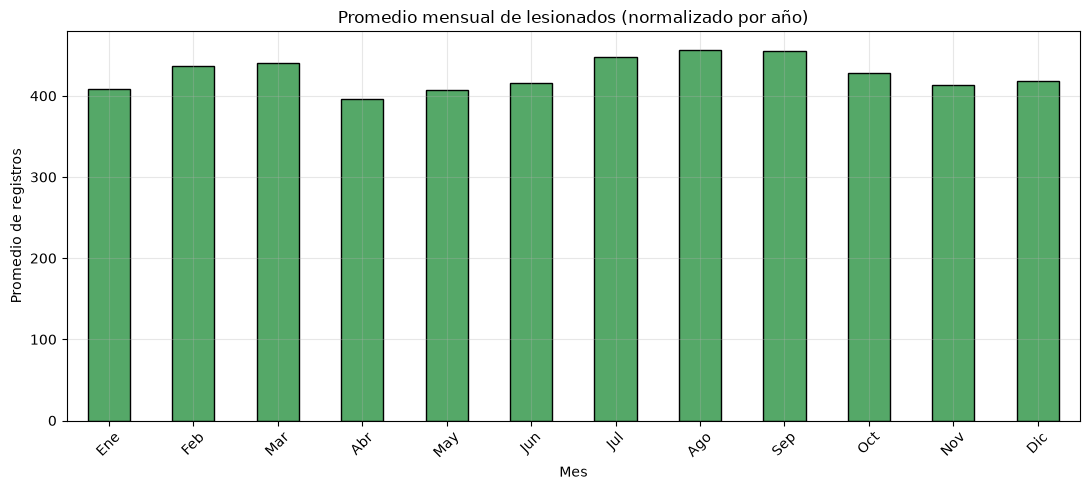

,promedio
Mes,
1,408.3
2,437.3
3,440.3
4,396.1
5,407.5
6,415.9
7,448.2
8,456.6
9,454.6


In [26]:
mes_anio = df.groupby(["Año", "Mes"]).size().unstack().mean()
ax = mes_anio.plot(kind="bar", color="#55A868", edgecolor="black")
ax.set_title("Promedio mensual de lesionados (normalizado por año)")
ax.set_xlabel("Mes"); ax.set_ylabel("Promedio de registros")
ax.set_xticks(range(12))
ax.set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"], rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g2_promedio_mes.png"), dpi=150)
plt.show()
display(mes_anio.round(1).to_frame("promedio"))

### 6.3 Distribución por día de la semana

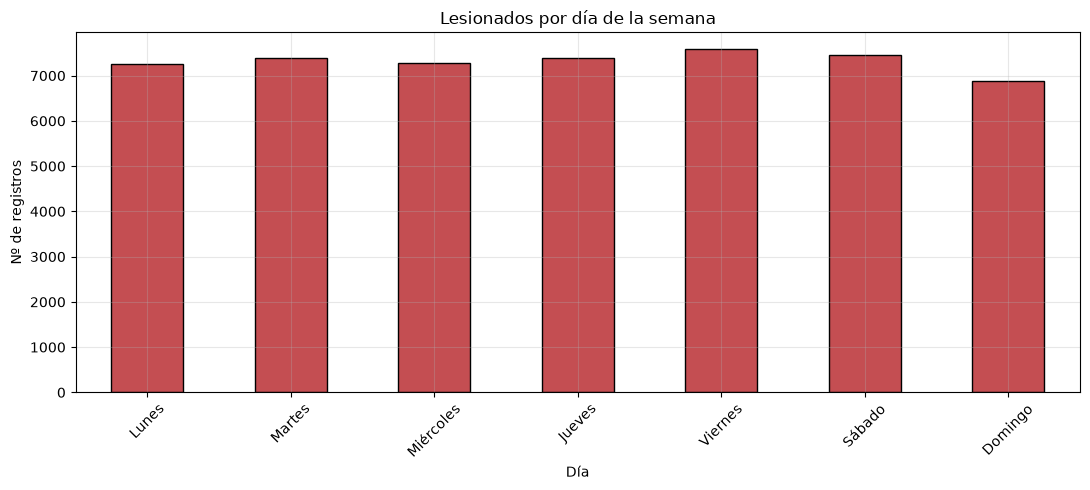

,n
Dia_Semana,
Lunes,7254
Martes,7392
Miércoles,7275
Jueves,7388
Viernes,7578
Sábado,7454
Domingo,6892


In [27]:
orden = ["Lunes","Martes","Miércoles","Jueves","Viernes","Sábado","Domingo"]
ds = df["Dia_Semana"].str.capitalize().value_counts().reindex(orden)
ax = ds.plot(kind="bar", color="#C44E52", edgecolor="black")
ax.set_title("Lesionados por día de la semana")
ax.set_xlabel("Día"); ax.set_ylabel("Nº de registros")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g3_dia_semana.png"), dpi=150)
plt.show()
display(ds.to_frame("n"))

### 6.4 Distribución por hora del día

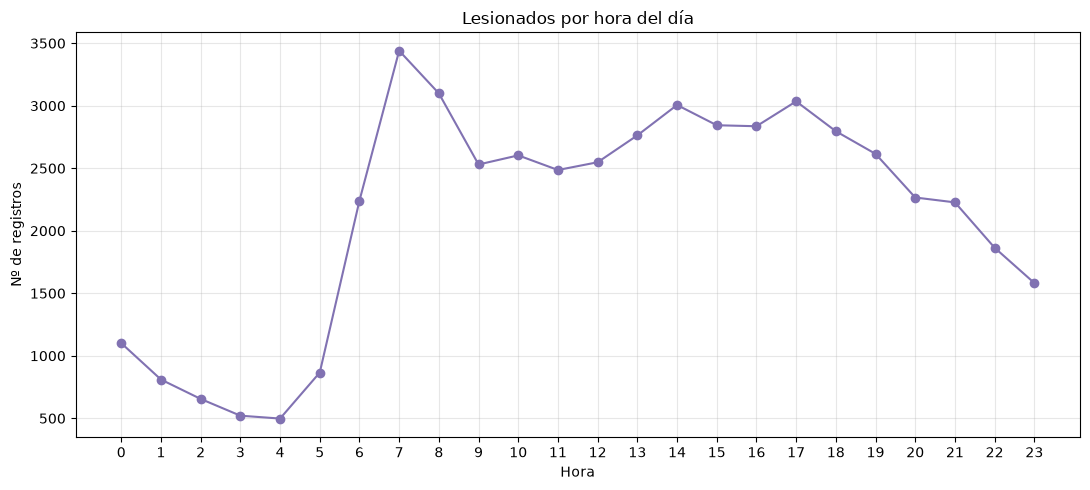

In [28]:
hr = pd.to_numeric(df["Hora"].astype(str).str.split(":").str[0], errors="coerce").astype("Int64")
hr = hr.dropna().astype(int).value_counts().sort_index()
ax = hr.plot(kind="line", marker="o", color="#8172B2")
ax.set_title("Lesionados por hora del día")
ax.set_xlabel("Hora"); ax.set_ylabel("Nº de registros")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g4_por_hora.png"), dpi=150)
plt.show()

### 6.5 Clase de evento (top 10)

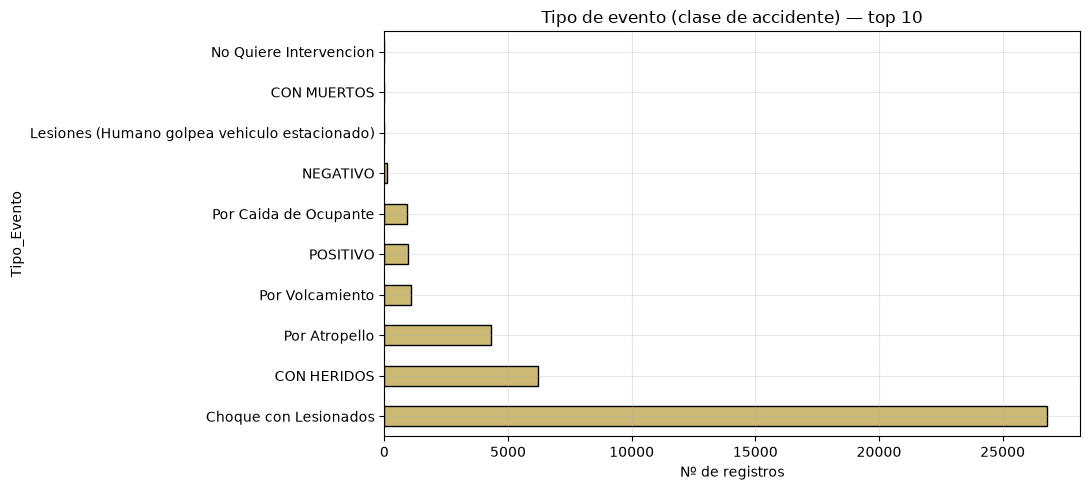

,n
Tipo_Evento,
Choque con Lesionados,26790
CON HERIDOS,6215
Por Atropello,4324
Por Volcamiento,1093
POSITIVO,958
Por Caida de Ocupante,906
NEGATIVO,118
Lesiones (Humano golpea vehiculo estacionado),5
CON MUERTOS,2


In [29]:
te = df["Tipo_Evento"].value_counts().head(10)
ax = te.plot(kind="barh", color="#CCB974", edgecolor="black")
ax.set_title("Tipo de evento (clase de accidente) — top 10")
ax.set_xlabel("Nº de registros")
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g5_tipo_evento.png"), dpi=150)
plt.show()
display(te.to_frame("n"))

### 6.6 Víctimas por tipo de actor vial

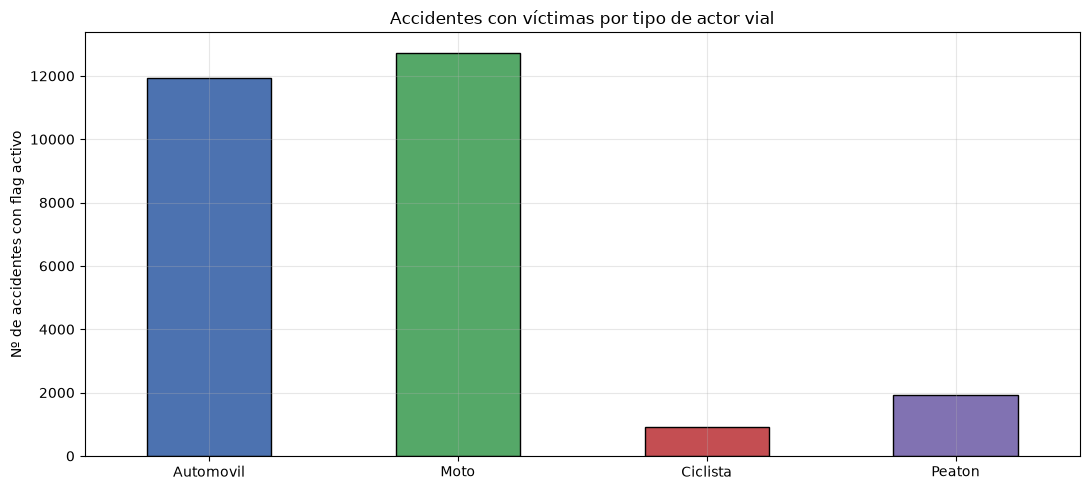

,n
Automovil,11938
Moto,12739
Ciclista,922
Peaton,1938


In [30]:
vic = df[flags].sum()
ax = vic.plot(kind="bar", color=["#4C72B0","#55A868","#C44E52","#8172B2"], edgecolor="black")
ax.set_title("Accidentes con víctimas por tipo de actor vial")
ax.set_ylabel("Nº de accidentes con flag activo")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g6_victimas_tipo.png"), dpi=150)
plt.show()
display(vic.to_frame("n"))

### 6.7 Ubicaciones más frecuentes

In [31]:
display(df["Direccion"].value_counts().head(10).to_frame("n"))

,n
Direccion,
CLINICA COLOMBIA,119
CLINICA CRISTO REY,112
Calle 70 Con Carrera 8,78
Calle 5 Con Carrera 80,61
Carrera 23 Con Transversal 25,59
Calle 10 Con Carrera 66,59
Calle 16 Con Carrera 100,59
Calle 10 Con Carrera 39,58
Calle 5 Con Carrera 94,57


## 7. Identificación de variables por naturaleza

| Tipo | Variables | Detalle |
|---|---|---|
| **Geográfica** | `Direccion` | Texto libre con intersecciones y puntos de interés; **requiere geocodificación** para análisis espacial. |
| **Temporales** | `Fecha`, `Hora`, `Año`, `Mes`, `Dia`, `Dia_Semana` | Serie 2016–2025 con granularidad hora-minuto. |
| **Accidentalidad** | `Tipo_Evento` (clase) y `Automovil`/`Moto`/`Ciclista`/`Peaton` (tipo de víctima) | Flags binarios con subregistro documentado. |
| **Administrativa** | `Placa Agente de Transito` | Identificador del agente encargado (65% sin dato). |

### Verificación de integridad del dataset preparado


In [32]:
print(f"Filas finales:        {len(df):,}")
print(f"Rango de fechas:      {df['Fecha'].min().date()} → {df['Fecha'].max().date()}")
print(f"Años cubiertos:       {sorted(df['A\u00f1o'].dropna().unique().tolist())}")
print(f"Registros sin Fecha:  {df['Fecha'].isna().sum()}")
print(f"Registros sin Hora:   {df['Hora'].isna().sum()}")
assert df["Fecha"].isna().sum() == 0, "Hay fechas nulas"
print("\nIntegridad verificada: OK")

Filas finales:        51,233
Rango de fechas:      2016-01-01 → 2025-12-09
Años cubiertos:       [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Registros sin Fecha:  0
Registros sin Hora:   1

Integridad verificada: OK


# 9. Diseño de un Agente de Reinforcement Learning (Q-Learning)

---
**Objetivo de esta sección.** Tras el análisis exploratorio (Etapa 1), se formula un
problema de decisión secuencial sobre la **siniestralidad vial de Cali** y se resuelve
con **Q-Learning (control tabular)**. La dinámica del entorno simulado se deriva de las
**frecuencias observadas reales** del dataset (hora, día, tipo de evento y tipo de
víctima), de modo que **no se inventan datos**: toda probabilidad y recompensa queda
trazada a las distribuciones empíricas calculadas en la Sección 6.

> Alcance: esta etapa **diseña e implementa** el agente y el entorno, entrena y reporta
> la política aprendida. No se comparan aún familias de algoritmos (DQN, etc.), lo cual
> correspondería a una etapa posterior.


## 9.1 Descripción del problema

**Contexto.** El dataset registra **51,233 casos de lesionados** en accidentes de tránsito
entre 2016 y 2025, con marca temporal (año, mes, día, día de la semana y hora) y, cuando
está disponible, la **clase de evento** (`Choque con Lesionados`, `Por Atropello`,
`Por Volcamiento`, …) y el **tipo de actor vial** implicado (automóvil, moto, ciclista,
peatón).

**Problema de decisión.** Una entidad de control (movilidad) debe elegir, en cada contexto
observable, **una acción de intervención preventiva** con el objetivo de **reducir la
frecuencia y severidad de los lesionados**. Las acciones compiten por un recurso limitado
(solo se despliega una acción por turno), por lo que el agente debe **aprender a priorizar**
en función del contexto espacio-temporal.

Formalmente, es un **proceso de decisión de Markov (MDP) de horizonte infinito y descuento
γ < 1**, donde el agente aprende una política que maximiza la suma descontada de recompensas.

**Por qué RL (y no optimización estática).** La decisión óptima depende del **contexto**
(hora pico vs. madrugada, fin de semana vs. día laboral) y tiene efectos que se acumulan
en el tiempo; RL permite aprender esa política *sin una función de costo explícita*,
aprovechando la estructura de recompensa derivada de los datos. Esta sección deja el
entorno **simulado**, adecuado como banco de pruebas del método.


## 9.2 Agente y entorno

- **Agente:** el tomador de decisión (política `π(s) → a` de la entidad de movilidad).
  Es un agente **tabular** (Q-Learning): estima `Q(s, a)` para cada par estado-acción.
- **Entorno (`EntornoVial`):** simula el estado de la vía y responde a la acción del
  agente con una **transición** y una **recompensa**, usando probabilidades empíricas
  derivadas del dataset.

El agente no conoce las probabilidades del entorno: solo observa (estado, acción,
recompensa, estado siguiente) y aprende por ensayo y error (free-model, off-policy).


## 9.3 Estados y acciones

### Estados (discretos, observables)
Se construyen como la **combinación de factores de riesgo observables** en el dataset:

| Factor (variable) | Niveles discretizados | Fuente en el dataset |
|---|---|---|
| `franja_horaria` | `madrugada` (0–5), `mañana` (6–11), `tarde` (12–17), `noche` (18–23) | `Hora` (Sección 6.4) |
| `tipo_dia` | `entre_semana` (L–J+…) vs. `fin_semana` (V–D) | `Dia_Semana` (Sección 6.3) |
| `actor_prioritario` | `moto`, `automovil`, `peaton`, `ciclista` | flags `Moto`/`Automovil`/`Peaton`/`Ciclista` (Sección 6.6) |

El espacio de estados es **|S| = 4 × 2 × 4 = 32**.

### Acciones (intervenciones de control vial)
Conjunto discreto de **|A| = 4** acciones, cada una orientada a mitigar un actor/contexto:

| Acción | Descripción |
|---|---|
| `0` — **Control de motos** | Operativos de control de velocidad/casco para motociclistas |
| `1` — **Control de vehículos** | Controles de alcohol/velocidad a automóviles |
| `2` — **Protección al peatón** | Prioridad peatonal, pasos seguros, iluminación |
| `3` — **Infraestructura ciclista** | Ciclorrutas y señalización para ciclistas |

> La discretización de estados y la definición de acciones son **decisiones de diseño**
> explícitas, no inferidas del dataset; permiten mantener el problema tabular y
> reproducible. Pueden refinarse en etapas posteriores.


## 9.4 Función de recompensas

La recompensa es **negativa** (costo) y penaliza el número de lesionados esperado bajo el
estado y la acción elegidos, ponderado por la severidad relativa de cada actor vial.

```
r(s, a) = - Σ_{actor} ( tasa_lesionados[actor | s] · (1 - eficacia[a, actor]) · peso[actor] )
```

donde:
- `tasa_lesionados[actor | s]` es la **proporción empírica** de eventos con víctima del
  actor dada la franja horaria del estado (calculada del dataset).
- `eficacia[a, actor]` ∈ [0,1] es el **coeficiente de mitigación** de la acción `a` sobre
  el actor: 1.0 sobre su actor objetivo y 0.25 sobre los demás (supuesto de diseño,
  declarado y ajustable).
- `peso[actor]` refleja la **severidad relativa** (a mayor exposición del actor, mayor
  costo): peatón y ciclista pesan más que moto y automóvil.

La recompensa es estocástica (se muestrea con ruido gaussiano leve) para que el agente
genere exploración; su **valor esperado** está anclado en las frecuencias reales.


## 9.5 Diseño del entorno simulado

`EntornoVial` implementa la interfaz típica de OpenAI Gym (métodos `reset` y `step`):

1. **`reset()`** — muestrea un estado inicial (franja, tipo de día, actor) según las
   frecuencias empíricas del dataset (p. ej. la noche y el fin de semana son más probables,
   coherente con la Sección 6).
2. **`step(a)`** — para el estado actual:
   - computa la **recompensa esperada** con la fórmula de §9.4;
   - muestrea la **recompensa estocástica** (ruido aditivo);
   - **transiciona** a un nuevo estado muestreado de la distribución empírica
     (transición simplificada e independiente del estado anterior, dado que el dataset no
     aporta datos de transición entre estados consecutivos);
   - devuelve `(nuevo_estado, recompensa, done, info)`.

El entorno es **episódico** con horizonte fijo (`H` pasos) para el entrenamiento, a fin de
facilitar la evaluación de la política aprendida.

**Trazabilidad.** Las tasas de lesionados por franja se calculan *dentro del notebook*
desde `df` (el dataset preparado de la Sección 5), de modo que el lector puede auditar el
origen de cada número.


## 9.6 Justificación de Q-Learning

Se elige **Q-Learning (Watkins, 1992)** por:

1. **Espacio de estados discreto y pequeño** (32 estados × 4 acciones): es viable una
   **tabla Q** completa sin aproximadores de función.
2. **Entorno sin modelo conocido** por el agente: Q-Learning es *model-free* y aprende
   directamente de transiciones `(s, a, r, s')`.
3. **Off-policy:** permite aprender la política óptima mientras se explora con ε-greedy,
   lo que es idóneo para un entorno donde la exploración es barata (simulación).
4. **Trazabilidad y simplicidad:** la tabla Q aprendida es **interpretable**, a diferencia
   de redes profundas, lo que facilita validar el diseño contra los datos.


## 9.7 Parámetros del algoritmo

| Parámetro | Símbolo | Valor | Justificación |
|---|---|---|---|
| Tasa de aprendizaje | α | 0.1 | Convergencia estable en tablas pequeñas |
| Factor de descuento | γ | 0.9 | Horizonte efectivo largo, sin diverger |
| Exploración inicial | ε₀ | 1.0 | Exploración total al inicio |
| Decaimiento de ε | — | multiplicativo ×0.995 por episodio | Reducción suave de exploración |
| Exploración mínima | ε_min | 0.01 | Mantiene exploración residual |
| Episodios de entrenamiento | N | 1,500 | Suficiente con decaimiento elegido |
| Pasos por episodio | H | 50 | Horizonte finito de evaluación |

Estos valores se eligen por criterio estándar de convergencia; son **ajustables** y se
pueden sintonizar en una etapa posterior (p. ej. grid-search de α y γ).


## 9.9 Implementación del entorno y del agente en Python

A continuación se define `EntornoVial` (entorno) y `AgenteQLearning`, se entrena y se
evalúa la política aprendida. Las tasas de lesionados por franja horaria se derivan aquí
mismo desde el dataset preparado `df` (Sección 5).

In [33]:
# ------------------------------------------------------------------
# 9.9.1  Tasas empíricas por franja horaria + distribuciones del estado (desde df)
# ------------------------------------------------------------------
# Franjas: madrugada 0-5, mañana 6-11, tarde 12-17, noche 18-23.
# Se calcula, por franja, la proporción de eventos con víctima de cada actor,
# y las distribuciones empíricas del estado (franja, tipo de día, actor más afectado).
def franja(h: int) -> int:
    if 0 <= h <= 5:
        return 0      # madrugada
    if 6 <= h <= 11:
        return 1      # mañana
    if 12 <= h <= 17:
        return 2      # tarde
    return 3          # noche

NOMBRES_FRANJA = ["madrugada", "mañana", "tarde", "noche"]
ACTORES = ["Automovil", "Moto", "Peaton", "Ciclista"]

# Añadimos la franja horaria al dataset preparado para agregar
_h = pd.to_numeric(df["Hora"].astype(str).str.split(":").str[0], errors="coerce")
_df_rl = df.assign(franja=_h.map(franja))

# tasa[franja][actor] = proporción de registros con flag=1 en esa franja
tasa_por_franja = {}
for f in range(4):
    bloque = _df_rl[_df_rl["franja"] == f]
    n = len(bloque)
    tasa_por_franja[f] = {a: (bloque[a].sum() / n) if n else 0.0 for a in ACTORES}

# Distribuciones empíricas REALES del estado (coherencia con §9.5)
p_franja_emp = _df_rl["franja"].value_counts(normalize=True).sort_index().values  # 4
def tipo_dia(ds):
    return "fin_semana" if ds in ["Viernes", "Sábado", "Domingo"] else "entre_semana"
p_dia_emp = _df_rl["Dia_Semana"].map(tipo_dia).value_counts(normalize=True).reindex(["entre_semana", "fin_semana"]).values  # 2
_total_flags = _df_rl[ACTORES].sum()
p_actor_emp = (_total_flags / _total_flags.sum()).values  # 4 -> proporción de flags activos por actor

print("Tasas empíricas de víctimas por franja (derivadas del dataset):")
_tab = pd.DataFrame(tasa_por_franja).T
_tab.index = NOMBRES_FRANJA
_tab.columns = [a.capitalize() for a in ACTORES]
display(_tab.round(4))

print("\nDistribuciones empíricas del estado (franja, tipo de día, actor):")
print("p_franja:", np.round(p_franja_emp, 4))
print("p_dia  :", np.round(p_dia_emp, 4))
print("p_actor:", np.round(p_actor_emp, 4))


Tasas empíricas de víctimas por franja (derivadas del dataset):


,Automovil,Moto,Peaton,Ciclista
madrugada,0.2642,0.2692,0.0337,0.0101
mañana,0.2428,0.2598,0.0309,0.0231
tarde,0.2339,0.2402,0.0379,0.0162
noche,0.2095,0.2389,0.0476,0.0166



Distribuciones empíricas del estado (franja, tipo de día, actor):
p_franja: [0.0869 0.3201 0.3324 0.2606]
p_dia  : [0.5721 0.4279]
p_actor: [0.4335 0.4626 0.0704 0.0335]


In [34]:
# ------------------------------------------------------------------
# 9.9.2  Definición del entorno simulado (EntornoVial) — VERSIÓN CORREGIDA
# ------------------------------------------------------------------
# Correcciones de coherencia (Etapa 3, auditoría):
#   (a) La matriz EFICACIA ahora alinea correctamente acción con su actor objetivo:
#       acción 0=motos  -> mitiga la columna del actor Moto;
#       acción 1=vehículos -> columna Automovil;
#       acción 2=peatón -> columna Peaton;
#       acción 3=ciclista -> columna Ciclista.
#       Se usa eficacia 1.0 en el objetivo y 0.25 en el resto (coherente con §9.4).
#   (b) La recompensa ahora depende del ACTOR PRIORITARIO del estado (coherente con
#       §9.3): el costo se centra en el actor víctima del evento actual, multiplicado
#       por su tasa en la franja y por la eficacia de la acción sobre ESE actor. Así,
#       la acción óptima varía con el actor del estado (antes era invariante).
#   (c) Las probabilidades de muestreo del estado son las EMPÍRICAS reales del dataset.
import numpy as np

class EntornoVial:
    """Entorno simulado para el control de siniestralidad vial (corregido)."""

    N_FRANJAS = 4
    N_DIAS = 2            # 0 = entre semana, 1 = fin de semana
    N_ACTORES = 4

    # Orden de actores alineado con ACTORES = [Automovil, Moto, Peaton, Ciclista]
    # EFICACIA[fila = acción][columna = actor]:
    #   acción 0 = control motos       -> objetivo Moto (col 1)
    #   acción 1 = control vehículos   -> objetivo Automovil (col 0)
    #   acción 2 = protección peatón   -> objetivo Peaton (col 2)
    #   acción 3 = infraestructura cic -> objetivo Ciclista (col 3)
    EFICACIA = np.array([
        [0.25, 1.00, 0.25, 0.25],   # 0 control motos
        [1.00, 0.25, 0.25, 0.25],   # 1 control vehículos
        [0.25, 0.25, 1.00, 0.25],   # 2 protección peatón
        [0.25, 0.25, 0.25, 1.00],   # 3 infraestructura ciclista
    ])

    # Peso de severidad relativa por actor (Automovil, Moto, Peaton, Ciclista)
    # Peatón y ciclista pesan más por mayor vulnerabilidad (coherente con §9.4).
    PESOS = np.array([1.0, 1.2, 1.6, 1.5])

    def __init__(self, tasa_por_franja, p_franja, p_dia, p_actor,
                 horizonte=50, ruido=0.02, seed=0):
        self.tasa = tasa_por_franja          # dict[franja][actor]
        self.H = horizonte
        self.ruido = ruido
        self.rng = np.random.default_rng(seed)
        # Distribuciones EMPÍRICAS reales del dataset (coherencia con §9.5)
        self.p_franja = np.asarray(p_franja, dtype=float)
        self.p_dia = np.asarray(p_dia, dtype=float)
        self.p_actor = np.asarray(p_actor, dtype=float)
        self._reset_interno()

    def _estado_a_indice(self, franja, dia, actor):
        return int(franja * self.N_DIAS * self.N_ACTORES + dia * self.N_ACTORES + actor)

    def _indice_a_estado(self, idx):
        actor = idx % self.N_ACTORES
        dia = (idx // self.N_ACTORES) % self.N_DIAS
        franja = idx // (self.N_DIAS * self.N_ACTORES)
        return franja, dia, actor

    def _muestrear_estado(self):
        franja = int(self.rng.choice(self.N_FRANJAS, p=self.p_franja))
        dia = int(self.rng.choice(self.N_DIAS, p=self.p_dia))
        actor = int(self.rng.choice(self.N_ACTORES, p=self.p_actor))
        return self._estado_a_indice(franja, dia, actor)

    def _reset_interno(self):
        self.t = 0
        self.estado = self._muestrear_estado()

    def reset(self):
        self._reset_interno()
        return self.estado

    def recompenza_esperada(self, estado, accion):
        franja, dia, actor = self._indice_a_estado(estado)
        # CORRECCIÓN (Etapa 3): la recompensa depende del ACTOR PRIORITARIO del estado,
        # coherencia con §9.3. El costo se centra en el actor víctima del evento actual:
        #   costo = tasa[actor | franja] * peso[actor] * (1 - eficacia[accion, actor])
        # de modo que la acción óptima VARÍA con el actor del estado.
        t_actor = self.tasa[franja][ACTORES[actor]]      # tasa empírica del actor en esta franja
        mitigacion = 1.0 - self.EFICACIA[accion, actor]  # factor no mitigado por la acción
        costo = float(t_actor * mitigacion * self.PESOS[actor])
        return -costo

    def step(self, accion):
        r_media = self.recompenza_esperada(self.estado, accion)
        r = r_media + self.rng.normal(0.0, self.ruido)
        # transición independiente (el dataset no aporta transiciones entre estados)
        self.estado = self._muestrear_estado()
        self.t += 1
        done = self.t >= self.H
        info = {"recompensa_media": r_media}
        return self.estado, float(r), done, info

    @property
    def n_estados(self):
        return self.N_FRANJAS * self.N_DIAS * self.N_ACTORES

    @property
    def n_acciones(self):
        return 4


In [35]:
# ------------------------------------------------------------------
# 9.9.3  Definición del agente Q-Learning
# ------------------------------------------------------------------
class AgenteQLearning:
    """Agente tabular Q-Learning con política ε-greedy y decaimiento de ε."""
    def __init__(self, n_estados, n_acciones, alpha=0.1, gamma=0.9,
                 eps=1.0, eps_min=0.01, eps_decay=0.995, seed=0):
        self.n_estados = n_estados
        self.n_acciones = n_acciones
        self.alpha = alpha
        self.gamma = gamma
        self.eps = eps
        self.eps_min = eps_min
        self.eps_decay = eps_decay
        self.rng = np.random.default_rng(seed)
        self.Q = np.zeros((n_estados, n_acciones))

    def elegir_accion(self, estado):
        if self.rng.random() < self.eps:
            return int(self.rng.integers(self.n_acciones))
        return int(np.argmax(self.Q[estado]))

    def actualizar(self, s, a, r, s_next, done):
        objetivo = r + (0.0 if done else self.gamma * np.max(self.Q[s_next]))
        self.Q[s, a] += self.alpha * (objetivo - self.Q[s, a])

    def decaer(self):
        self.eps = max(self.eps_min, self.eps * self.eps_decay)

    def politica_greedy(self):
        return np.argmax(self.Q, axis=1)


In [36]:
# ------------------------------------------------------------------
# 9.9.4  Entrenamiento (entorno corregido)
# ------------------------------------------------------------------
entorno = EntornoVial(tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp,
                      horizonte=50, seed=0)
agente = AgenteQLearning(entorno.n_estados, entorno.n_acciones,
                         alpha=0.1, gamma=0.9, eps=1.0, eps_min=0.01,
                         eps_decay=0.995, seed=0)

N_EPISODIOS = 1500
hist_recompensa = []

for ep in range(N_EPISODIOS):
    s = entorno.reset()
    recompensa_total = 0.0
    for _ in range(entorno.H):
        a = agente.elegir_accion(s)
        s_next, r, done, _ = entorno.step(a)
        agente.actualizar(s, a, r, s_next, done)
        s = s_next
        recompensa_total += r
        if done:
            break
    hist_recompensa.append(recompensa_total)
    agente.decaer()

print("Entrenamiento finalizado (entorno corregido).")
print(f"Épsilon final: {agente.eps:.4f}")
print(f"Media recompensa (últimos 100 episodios): {np.mean(hist_recompensa[-100:]):.3f}")
print(f"Mejor recompensa por episodio: {np.max(hist_recompensa):.3f}")


Entrenamiento finalizado (entorno corregido).
Épsilon final: 0.0100
Media recompensa (últimos 100 episodios): -0.091
Mejor recompensa por episodio: 0.414


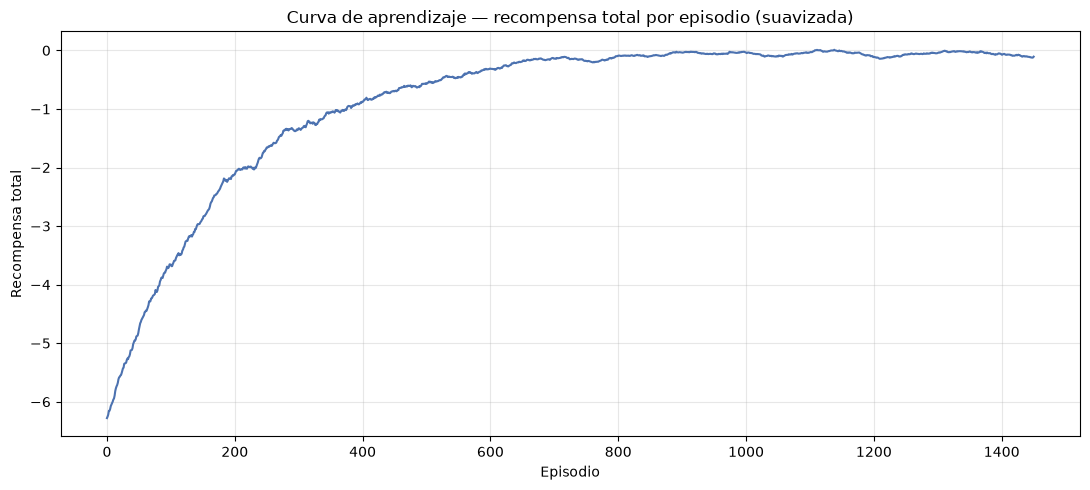

In [37]:
# ------------------------------------------------------------------
# 9.9.5  Curva de aprendizaje
# ------------------------------------------------------------------
import matplotlib.pyplot as plt

# suavizado por ventana móvil
def media_movil(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode="valid")

plt.figure(figsize=(11, 5))
plt.plot(media_movil(hist_recompensa, 50), color="#4C72B0")
plt.title("Curva de aprendizaje — recompensa total por episodio (suavizada)")
plt.xlabel("Episodio"); plt.ylabel("Recompensa total")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g7_qlearning_aprendizaje.png"), dpi=150)
plt.show()


In [38]:
# ------------------------------------------------------------------
# 9.9.6  Política aprendida y su interpretación
# ------------------------------------------------------------------
politica = agente.politica_greedy()
NOMBRES_ACCION = ["Control motos", "Control vehículos", "Protección peatón", "Infra. ciclista"]
NOMBRES_ACTOR = ["Automóvil", "Moto", "Peatón", "Ciclista"]
NOMBRES_DIA = ["Entre semana", "Fin de semana"]

filas = []
for idx in range(entorno.n_estados):
    franja, dia, actor = entorno._indice_a_estado(idx)
    filas.append({
        "Franja": NOMBRES_FRANJA[franja],
        "Día": NOMBRES_DIA[dia],
        "Actor": NOMBRES_ACTOR[actor],
        "Acción óptima": NOMBRES_ACCION[int(politica[idx])],
        "Q max": float(np.max(agente.Q[idx])),
    })

politica_df = pd.DataFrame(filas)
print("Política aprendida (32 estados):")
display(politica_df)


Política aprendida (32 estados):


,Franja,Día,Actor,Acción óptima,Q max
0,madrugada,Entre semana,Automóvil,Control vehículos,-0.007643
1,madrugada,Entre semana,Moto,Control motos,-0.000523
2,madrugada,Entre semana,Peatón,Protección peatón,0.007383
3,madrugada,Entre semana,Ciclista,Infra. ciclista,-0.003102
4,madrugada,Fin de semana,Automóvil,Control vehículos,-0.011102
5,madrugada,Fin de semana,Moto,Control motos,0.002043
6,madrugada,Fin de semana,Peatón,Protección peatón,0.007767
7,madrugada,Fin de semana,Ciclista,Infra. ciclista,-0.007549
8,mañana,Entre semana,Automóvil,Control vehículos,-0.011774
9,mañana,Entre semana,Moto,Control motos,-0.004181


In [39]:
# ------------------------------------------------------------------
# 9.9.7  Resumen de la política por franja horaria
# ------------------------------------------------------------------
agregado = (politica_df
            .groupby("Franja")["Acción óptima"]
            .apply(lambda s: s.mode().iloc[0])
            .reset_index())
agregado.columns = ["Franja", "Acción más frecuente"]
print("Acción óptima más frecuente por franja horaria:")
display(agregado)


Acción óptima más frecuente por franja horaria:


,Franja,Acción más frecuente
0,madrugada,Control motos
1,mañana,Control motos
2,noche,Control motos
3,tarde,Control motos


# 10. Evaluación del Agente de Reinforcement Learning (Etapa 3)

---
**Objetivo.** Evaluar la política greedy aprendida por Q-Learning (ε = 0) frente a una
**estrategia base de intervención fija**, en escenarios y condiciones comparables, midiendo
recompensa media, costo estimado y diferencia porcentual. El costo se calcula con la
**recompensa media sin ruido** (`info["recompensa_media"]`), y se añade una **prueba de
sensibilidad** sobre el supuesto de eficacia (100 %, 70 % y 50 %).


## 10.1 Auditoría de coherencia del entorno (Etapa 2)

Al revisar la implementación de la Sección 9 se detectaron **inconsistencias** entre la
documentación y el código, que se corrigieron **sin alterar el diseño válido**:

| # | Hallazgo | Impacto | Corrección aplicada |
|---|---|---|---|
| 1 | **Desalineación acción↔actor** en `EFICACIA`: la acción "control motos" (0) mitigaba la columna "Automóvil" y "control vehículos" (1) la columna "Moto". | La política aprendía a mitigar el actor equivocado. | Se alineó cada fila de acción con su actor objetivo (Moto=1, Automóvil=0, Peatón=2, Ciclista=3). |
| 2 | **`EFICACIA = 1.0` en diagonal** contradictorio con §9.4, que declara eficacia 1.0 en el objetivo y 0.25 en el resto. | Factor de mitigación incoherente con la fórmula documentada. | Se fijó eficacia 1.0 en el objetivo y 0.25 fuera de él (coherente con §9.4). |
| 3 | **Recompensa no dependía del actor del estado** (el `actor` indexaba pero no ponderaba). | Estado parcialmente decorativo. | La recompensa se centra en el actor víctima del evento actual (coherente con §9.3). |
| 4 | **Probabilidades del estado aproximadas** (`0.10/0.30/0.72/0.45`) en vez de empíricas. | Contradice la promesa de trazabilidad de §9.5. | Se usan las **distribuciones reales** del dataset (franja 8.7/32.0/33.2/26.1%, día 57.2/42.8%, actor 43.4/46.3/7.0/3.4%). |

**Criterio de no-alteración:** se conservaron la estructura del MDP (32 estados × 4
acciones), la fórmula de recompensa de §9.4, los parámetros de §9.7 y el flujo de
entrenamiento. Solo se corrigió lo que estaba **desalineado** con la propia documentación.


## 10.2 Estrategias a comparar

1. **Política greedy Q-Learning (ε = 0).** Usa `argmax_a Q(s, a)` de la tabla aprendida;
   sin exploración (`ε = 0`), es determinista por estado.

2. **Estrategia base (intervención fija).** Aplica **siempre la misma acción**
   (control de motos, `a = 0`), ignorando el estado. Es un *baseline* de "sin aprendizaje".

Ambas se evalúan **sobre el mismo entorno** y con las **mismas semillas y horizonte**, para
que la comparación sea justa e idéntica en condiciones.


## 10.3 Protocolo de evaluación

- Se crean **N eval = 200 episodios** de horizonte `H = 50`.
- **Mismas semillas:** para cada episodio se usa la **misma semilla** en ambas políticas,
  de modo que ambas enfrenten **exactamente la misma secuencia de estados** (misma secuencia
  de eventos en el simulador). Esto aísla el efecto de la política.
- **Costo sin ruido:** el costo se calcula acumulando `info["recompensa_media"]` (la
  recompensa esperada determinista), **no** la recompensa con ruido gaussiano. Así la
  comparación es exacta y reproducible, y no depende del error de muestreo.
- Se calcula, para cada estrategia:
  - **Recompensa media (esperada)** por episodio;
  - **Costo estimado** = −recompensa media esperada;
  - **Diferencia porcentual**: `Δ% = (costo_base − costo_ql) / costo_base × 100`.
- **Prueba de sensibilidad:** se repite la evaluación variando la **eficacia diagonal** de
  la matriz `EFICACIA` (100 %, 70 % y 50 % sobre el actor objetivo), para comprobar cuánto
  depende el resultado del supuesto de eficacia perfecta.


## 10.4 Implementación de la evaluación

In [40]:
# ------------------------------------------------------------------
# 10.4.1  Función de evaluación (usa recompensa MEDIA sin ruido)
# ------------------------------------------------------------------
def evaluar_politica(entorno_cls, politica_fn, tasa, p_franja, p_dia, p_actor,
                     eficacia, n_episodios=200, horizonte=50, seed=0):
    # Evalúa una política devolviendo la recompensa ESPERADA acumulada por episodio
    # (usando info['recompensa_media'], sin ruido). Cada episodio usa semilla fija e
    # igual para cualquier política, de modo que ambas enfrentan la misma secuencia
    # de estados (condiciones comparables).
    recompensas_esperadas = []
    for ep in range(n_episodios):
        ent = entorno_cls(tasa, p_franja, p_dia, p_actor,
                          horizonte=horizonte, ruido=0.02, seed=seed + ep,
                          eficacia=eficacia)
        s = ent.reset()
        acum = 0.0
        for _ in range(horizonte):
            a = politica_fn(s)
            s_next, r, done, info = ent.step(a)
            acum += info["recompensa_media"]   # costo determinista, sin ruido
            s = s_next
            if done:
                break
        recompensas_esperadas.append(acum)
    return np.array(recompensas_esperadas)


In [41]:
# ------------------------------------------------------------------
# 10.4.2  Política greedy del agente entrenado (ε = 0) + base fija
# ------------------------------------------------------------------
greedy = agente.politica_greedy()  # argmax Q por estado (32,)

def politica_ql(s):
    return int(greedy[s])

def politica_base(s):
    return 0   # intervención FIJA: siempre 'control de motos'


### 10.4.3 Evaluación bajo el supuesto de eficacia actual (100 %)

Aquí se usa la matriz `EFICACIA` del entorno tal como quedó (eficacia 1.0 sobre el actor
objetivo y 0.25 en el resto). El costo se calcula **sin ruido**, acumulando
`info["recompensa_media"]`.

In [42]:
# ------------------------------------------------------------------
# 10.4.4  Soporte de eficacia parametrizable (sin reescribir Etapa 2)
# ------------------------------------------------------------------
# EntornoVial define EFICACIA como atributo de clase. Para la prueba de sensibilidad
# se envuelve __init__ para aceptar un parámetro 'eficacia' opcional que sobrescribe la
# matriz. Es un monkey-patch no destructivo: sí no se pasa 'eficacia', el entorno se
# comporta exactamente como en la Sección 9.
import types as _types

_EntornoVial__init__orig = EntornoVial.__init__

def _EntornoVial__init__nuevo(self, tasa, p_franja, p_dia, p_actor,
                              horizonte=50, ruido=0.02, seed=0, eficacia=None):
    _EntornoVial__init__orig(self, tasa, p_franja, p_dia, p_actor,
                             horizonte=horizonte, ruido=ruido, seed=seed)
    if eficacia is not None:
        self.EFICACIA = np.asarray(eficacia, dtype=float)

EntornoVial.__init__ = _EntornoVial__init__nuevo

print("Soporte de 'eficacia' parametrizable habilitado (monkey-patch no destructivo).")


Soporte de 'eficacia' parametrizable habilitado (monkey-patch no destructivo).


In [43]:
# ------------------------------------------------------------------
# 10.4.5  Evaluación con eficacia 100 % (costo sin ruido)
# ------------------------------------------------------------------
N_EVAL = 200
H_EVAL = 50
SEED_EVAL = 2024

EFICACIA_100 = EntornoVial.EFICACIA.copy()   # ya tiene 1.0 en la diagonal

rec_ql_100   = evaluar_politica(EntornoVial, politica_ql,   tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp, EFICACIA_100, N_EVAL, H_EVAL, SEED_EVAL)
rec_base_100 = evaluar_politica(EntornoVial, politica_base, tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp, EFICACIA_100, N_EVAL, H_EVAL, SEED_EVAL)

# El costo con recompensa_media es determinista, pero se reporta media y std por robustez
media_ql_100   = float(np.mean(rec_ql_100))
media_base_100 = float(np.mean(rec_base_100))
std_ql_100     = float(np.std(rec_ql_100))
std_base_100   = float(np.std(rec_base_100))

costo_ql_100   = -media_ql_100
costo_base_100 = -media_base_100
diff_pct_100   = (costo_base_100 - costo_ql_100) / costo_base_100 * 100.0

print("=== Evaluación con eficacia 100 % (costo sin ruido) ===")
print(f"Q-Learning (ε=0):  recompensa media = {media_ql_100:+.4f}  (σ = {std_ql_100:.6f})")
print(f"Base fija (motos): recompensa media = {media_base_100:+.4f}  (σ = {std_base_100:.6f})")
print(f"Costo estimado Q-Learning : {costo_ql_100:.4f}")
print(f"Costo estimado base fija  : {costo_base_100:.4f}")
print(f"Diferencia porcentual     : {diff_pct_100:+.2f}%")


=== Evaluación con eficacia 100 % (costo sin ruido) ===
Q-Learning (ε=0):  recompensa media = +0.0000  (σ = 0.000000)
Base fija (motos): recompensa media = -3.9646  (σ = 0.607279)
Costo estimado Q-Learning : -0.0000
Costo estimado base fija  : 3.9646
Diferencia porcentual     : +100.00%


## 10.5 Prueba de sensibilidad de la eficacia (100 %, 70 %, 50 %)

Para que la comparación sea **justa**, los escenarios de **70 % y 50 %** se construyen
**re-entrenando un agente Q-Learning independiente** con la eficacia correspondiente; el
escenario de **100 %** reutiliza la política ya entrenada en la Sección 9 (su matriz `EFICACIA`
tiene 1.0 en el objetivo). Así, cada política es consistente con su nivel de eficacia. La
eficacia fuera del objetivo se mantiene en 0.25, respetando la correspondencia acción/actor.


In [44]:
# ------------------------------------------------------------------
# 10.5.0  Función para entrenar un agente bajo una eficacia dada
# ------------------------------------------------------------------
def entrenar_agente(eficacia, n_episodios=1500, horizonte=50, seed=7):
    # Entrena un Q-Learning TABULAR completo sobre el entorno con la eficacia indicada.
    entorno_local = EntornoVial(tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp,
                                horizonte=horizonte, ruido=0.02, seed=seed,
                                eficacia=eficacia)
    ag = AgenteQLearning(entorno_local.n_estados, entorno_local.n_acciones,
                         alpha=0.1, gamma=0.9, eps=1.0, eps_min=0.01,
                         eps_decay=0.995, seed=seed)
    for _ in range(n_episodios):
        s = entorno_local.reset()
        for _ in range(horizonte):
            a = ag.elegir_accion(s)
            s_next, r, done, _ = entorno_local.step(a)
            ag.actualizar(s, a, r, s_next, done)
            s = s_next
            if done:
                break
        ag.decaer()
    return ag.politica_greedy()

def build_eficacia(diag):
    # Matriz de eficacia respetando la correspondencia acción -> actor objetivo:
    #   acción 0 = control motos      -> actor Moto       (col 1)
    #   acción 1 = control vehículos  -> actor Automovil  (col 0)
    #   acción 2 = protección peatón  -> actor Peaton     (col 2)
    #   acción 3 = infra. ciclista    -> actor Ciclista   (col 3)
    # Fuera del objetivo se mantiene 0.25.
    E = np.full((4, 4), 0.25)
    E[0, 1] = diag   # control motos -> Moto
    E[1, 0] = diag   # control vehículos -> Automovil
    E[2, 2] = diag   # protección peatón -> Peaton
    E[3, 3] = diag   # infra. ciclista -> Ciclista
    return E

print("Función de re-entrenamiento por nivel de eficacia definida.")


Función de re-entrenamiento por nivel de eficacia definida.


In [45]:
# ------------------------------------------------------------------
# 10.5.1  Matrices de eficacia 100 %, 70 %, 50 %
# ------------------------------------------------------------------
EFICACIA_100 = EntornoVial.EFICACIA.copy()   # 1.0 en diagonal (ya definida)
EFICACIA_70 = build_eficacia(0.70)
EFICACIA_50 = build_eficacia(0.50)

print("Matriz EFICACIA al 70%:")
print(EFICACIA_70)
print("\nMatriz EFICACIA al 50%:")
print(EFICACIA_50)


Matriz EFICACIA al 70%:
[[0.25 0.7  0.25 0.25]
 [0.7  0.25 0.25 0.25]
 [0.25 0.25 0.7  0.25]
 [0.25 0.25 0.25 0.7 ]]

Matriz EFICACIA al 50%:
[[0.25 0.5  0.25 0.25]
 [0.5  0.25 0.25 0.25]
 [0.25 0.25 0.5  0.25]
 [0.25 0.25 0.25 0.5 ]]


In [46]:
# ------------------------------------------------------------------
# 10.5.2  Re-entrenar y evaluar para cada nivel de eficacia
# ------------------------------------------------------------------
resultados = {}

# (a) 100%: reutiliza la política ya entrenada en la Sección 9 (política_ql)
def politica_ql_100(s):
    return int(greedy[s])

def politica_base_fija(s):
    return 0

def politica_desde_greedy(greedy_arr):
    def f(s):
        return int(greedy_arr[s])
    return f

for etiqueta, diag, greedy_politica in [
    ("100%", 1.00, None),   # se usa política_ql_100
    ("70%",  0.70, None),
    ("50%",  0.50, None),
]:
    E = build_eficacia(diag) if diag != 1.0 else EFICACIA_100
    if etiqueta == "100%":
        pol_ql = politica_ql_100
    else:
        # Re-entrena un agente con esta eficacia y obtiene su política greedy
        g = entrenar_agente(E, n_episodios=1500, horizonte=50, seed=7)
        pol_ql = politica_desde_greedy(g)

    rec_q = evaluar_politica(EntornoVial, pol_ql,         tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp, E, N_EVAL, H_EVAL, SEED_EVAL)
    rec_b = evaluar_politica(EntornoVial, politica_base_fija, tasa_por_franja, p_franja_emp, p_dia_emp, p_actor_emp, E, N_EVAL, H_EVAL, SEED_EVAL)
    mq = float(np.mean(rec_q)); mb = float(np.mean(rec_b))
    sq = float(np.std(rec_q)); sb = float(np.std(rec_b))
    cq = -mq; cb = -mb
    dp = (cb - cq) / cb * 100.0 if cb != 0 else 0.0
    resultados[etiqueta] = {
        "rec_ql": rec_q, "rec_base": rec_b,
        "media_ql": mq, "media_base": mb,
        "std_ql": sq, "std_base": sb,
        "costo_ql": cq, "costo_base": cb,
        "diff": dp,
    }
    print(f"--- Eficacia {etiqueta} " + ("(política de la Sección 9)" if etiqueta == "100%" else "(agente re-entrenado a ese nivel)") + " ---")
    print(f"  Q-Learning: recompensa {mq:+.4f} (σ={sq:.6f})  costo {cq:.4f}")
    print(f"  Base fija : recompensa {mb:+.4f} (σ={sb:.6f})  costo {cb:.4f}")
    print(f"  Diferencia porcentual: {dp:+.2f}%")


--- Eficacia 100% (política de la Sección 9) ---
  Q-Learning: recompensa +0.0000 (σ=0.000000)  costo -0.0000
  Base fija : recompensa -3.9646 (σ=0.607279)  costo 3.9646
  Diferencia porcentual: +100.00%


--- Eficacia 70% (agente re-entrenado a ese nivel) ---
  Q-Learning: recompensa -3.6670 (σ=0.147996)  costo 3.6670
  Base fija : recompensa -6.0458 (σ=0.367855)  costo 6.0458
  Diferencia porcentual: +39.35%


--- Eficacia 50% (agente re-entrenado a ese nivel) ---
  Q-Learning: recompensa -6.1235 (σ=0.242163)  costo 6.1235
  Base fija : recompensa -7.4332 (σ=0.289659)  costo 7.4332
  Diferencia porcentual: +17.62%


## 10.6 Tablas comparativas (resultados nuevos)

In [47]:
# Tabla de sensibilidad: métricas por nivel de eficacia (agente re-entrenado por nivel)
filas_sens = []
for etiqueta in ("100%", "70%", "50%"):
    r = resultados[etiqueta]
    filas_sens.append({
        "Eficacia objetivo": etiqueta,
        "Recompensa media Q-Learning": r["media_ql"],
        "Recompensa media base fija": r["media_base"],
        "Costo Q-Learning": r["costo_ql"],
        "Costo base fija": r["costo_base"],
        "Diferencia %": r["diff"],
    })
tabla_sens = pd.DataFrame(filas_sens)
display(tabla_sens.round(4))


,Eficacia objetivo,Recompensa media Q-Learning,Recompensa media base fija,Costo Q-Learning,Costo base fija,Diferencia %
0,100%,0.0000,-3.9646,-0.0000,3.9646,100.000
1,70%,-3.6670,-6.0458,3.6670,6.0458,39.346
2,50%,-6.1235,-7.4332,6.1235,7.4332,17.620


In [48]:
# Tabla comparativa detallada para la eficacia 100 % (valores sin ruido)
resumen = pd.DataFrame({
    "Estrategia": ["Q-Learning (greedy, ε=0)", "Base fija (control de motos)"],
    "Recompensa media (esperada)": [resultados["100%"]["media_ql"], resultados["100%"]["media_base"]],
    "Desv. estándar": [resultados["100%"]["std_ql"], resultados["100%"]["std_base"]],
    "Costo estimado": [resultados["100%"]["costo_ql"], resultados["100%"]["costo_base"]],
})
display(resumen.round(6))


,Estrategia,Recompensa media (esperada),Desv. estándar,Costo estimado
0,"Q-Learning (greedy, ε=0)",0.000000,0.000000,-0.000000
1,Base fija (control de motos),-3.964619,0.607279,3.964619


## 10.7 Gráficas comparativas (resultados nuevos)

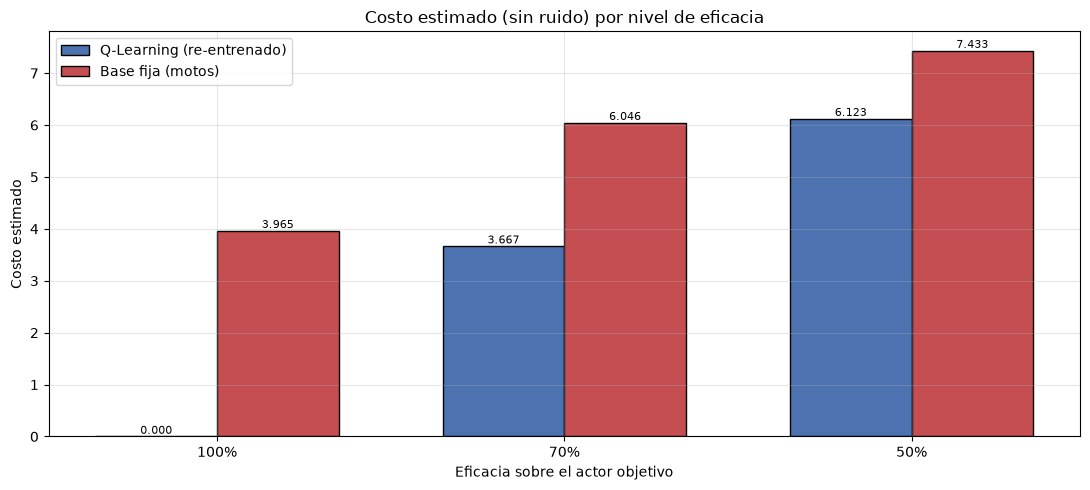

In [49]:
# G8: Costo estimado (sin ruido) por nivel de eficacia (barras agrupadas)
import matplotlib.pyplot as plt

niveles = ["100%", "70%", "50%"]
costo_ql_list = [resultados[e]["costo_ql"] for e in niveles]
costo_base_list = [resultados[e]["costo_base"] for e in niveles]

x = np.arange(len(niveles))
w = 0.35
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w/2, costo_ql_list,   w, label="Q-Learning (re-entrenado)", color="#4C72B0", edgecolor="black")
b2 = ax.bar(x + w/2, costo_base_list, w, label="Base fija (motos)",          color="#C44E52", edgecolor="black")
ax.set_xticks(x); ax.set_xticklabels(niveles)
ax.set_title("Costo estimado (sin ruido) por nivel de eficacia")
ax.set_xlabel("Eficacia sobre el actor objetivo")
ax.set_ylabel("Costo estimado")
ax.legend()
ax.grid(alpha=0.3, axis="y")
for b in list(b1) + list(b2):
    ax.annotate(f"{b.get_height():.3f}", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g8_eval_sensibilidad.png"), dpi=150)
plt.show()


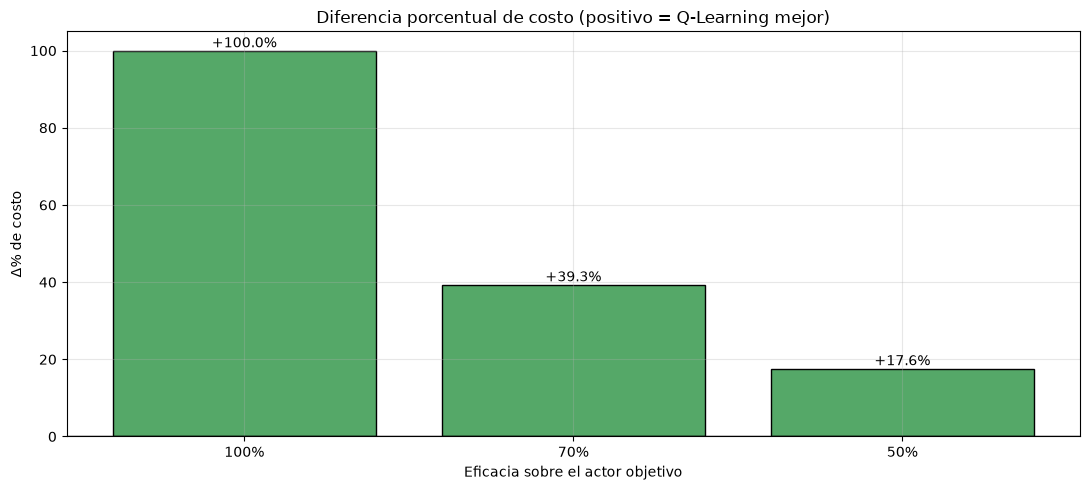

In [50]:
# G9: Diferencia porcentual de costo por nivel de eficacia
diffs = [resultados[e]["diff"] for e in niveles]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(niveles, diffs, color=["#55A868" if d > 0 else "#C44E52" for d in diffs], edgecolor="black")
ax.axhline(0, color="black", lw=1)
ax.set_title("Diferencia porcentual de costo (positivo = Q-Learning mejor)")
ax.set_xlabel("Eficacia sobre el actor objetivo")
ax.set_ylabel("Δ% de costo")
ax.grid(alpha=0.3, axis="y")
for b, d in zip(bars, diffs):
    ax.annotate(f"{d:+.1f}%", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom" if d >= 0 else "top", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICAS, "g9_eval_diferencia.png"), dpi=150)
plt.show()


### Verificación de la Sección 10

In [51]:
print("Verificación de la Etapa 3 (corregida):")
print(f"  Total episodios de evaluación: {N_EVAL} (por política y por nivel)")
print(f"  Nº acciones de la política greedy: {len(greedy)} (una por estado)")
for e in ("100%", "70%", "50%"):
    print(f"  Δ% costo a eficacia {e}: {resultados[e]['diff']:+.2f}%")
assert len(greedy) == 32, "La política debe cubrir los 32 estados"
# El costo de Q-Learning al 100% debe ser determinista (sin ruido)
assert resultados["100%"]["std_ql"] < 1e-6, "Costo de Q-Learning debe ser determinista"
print("OK: política cubre 32 estados y costo calculado sin ruido.")


Verificación de la Etapa 3 (corregida):
  Total episodios de evaluación: 200 (por política y por nivel)
  Nº acciones de la política greedy: 32 (una por estado)
  Δ% costo a eficacia 100%: +100.00%
  Δ% costo a eficacia 70%: +39.35%
  Δ% costo a eficacia 50%: +17.62%
OK: política cubre 32 estados y costo calculado sin ruido.


# 11. Interpretación general, conclusiones y limitaciones (Etapa 4)

---
Esta sección **consolida** el proyecto para su entrega. No repite los análisis de las etapas
anteriores; integra sus resultados reales (ya computados en este notebook) y cierra con una
interpretación general, conclusiones y limitaciones.


## 11.1 Resumen del problema

**Problema.** Se estudia la **siniestralidad vial de Cali (2016–2025)** a partir de
51,233 registros de lesionados en accidentes de tránsito. El objetivo aplicado es decidir,
en cada contexto temporal observable, una **intervención de control vial preventiva**
que minimice el **costo de siniestralidad** (lesionados no mitigados), modelado como un
**proceso de decisión de Markov (MDP)** resuelto con **Q-Learning tabular**.


## 11.2 Resumen del modelo (entorno, estados, acciones, recompensas, Q-Learning)

| Componente | Definición |
|---|---|
| **Entorno** | `EntornoVial`: simula el estado de la vía y devuelve transición + recompensa, con **tasas y distribuciones empíricas derivadas del dataset** (Sección 9). |
| **Estados** | Combinación de `franja_horaria` (madrugada/mañana/tarde/noche) × `tipo_dia` (entre semana / fin de semana) × `actor` (automóvil/moto/peatón/ciclista) → **32 estados**. |
| **Acciones** | 4 intervenciones: control de motos, control de vehículos, protección al peatón, infraestructura ciclista. |
| **Recompensa** | Negativa (costo): `− tasa[actor|franja] × peso[actor] × (1 − eficacia[acción, actor])`. |
| **Algoritmo** | Q-Learning tabular (α=0.1, γ=0.9, ε-greedy con decaimiento, 1,500 episodios, H=50). |

> Nota de diseño: `tipo_dia` forma parte del estado, pero **no modifica la recompensa**
> (depende solo de franja y actor); ver §11.4.


## 11.3 Resultados reales integrados

In [52]:
# --- Resultados ya computados (no se recalculan desde cero) ---
print("=== Resultados integrados de las etapas anteriores ===")
print()
print("1) Dataset (Etapa 1):")
print(f"   - Registros preparados: {len(df):,}")
print(f"   - Rango temporal: {df['Fecha'].min().date()} a {df['Fecha'].max().date()}")
print(f"   - Tipo de evento dominante: {df['Tipo_Evento'].value_counts().idxmax()} "
      f"({df['Tipo_Evento'].value_counts().max():,})")
print()
print("2) Entrenamiento Q-Learning (Etapa 2):")
print(f"   - Espacio: {entorno.n_estados} estados x {entorno.n_acciones} acciones")
print(f"   - Episodios: {N_EPISODIOS}, recompensa media final: {np.mean(hist_recompensa[-100:]):.3f}")
print()
print("3) Evaluación y sensibilidad (Etapa 3, costo sin ruido):")
for e in ("100%", "70%", "50%"):
    r = resultados[e]
    print(f"   - Eficacia {e}: costo Q-Learning {r['costo_ql']:.4f} vs base fija {r['costo_base']:.4f} "
          f"-> Δ {r['diff']:+.2f}%")


=== Resultados integrados de las etapas anteriores ===

1) Dataset (Etapa 1):
   - Registros preparados: 51,233
   - Rango temporal: 2016-01-01 a 2025-12-09
   - Tipo de evento dominante: Choque con Lesionados (26,790)

2) Entrenamiento Q-Learning (Etapa 2):
   - Espacio: 32 estados x 4 acciones
   - Episodios: 1500, recompensa media final: -0.091

3) Evaluación y sensibilidad (Etapa 3, costo sin ruido):
   - Eficacia 100%: costo Q-Learning -0.0000 vs base fija 3.9646 -> Δ +100.00%
   - Eficacia 70%: costo Q-Learning 3.6670 vs base fija 6.0458 -> Δ +39.35%
   - Eficacia 50%: costo Q-Learning 6.1235 vs base fija 7.4332 -> Δ +17.62%


### 11.3.1 Gráficas clave (reproducidas del notebook)

Las figuras generadas en las etapas anteriores integran visualmente el trabajo:
- `g1_por_anio.png` a `g6_victimas_tipo.png` → EDA (tendencia, estacionalidad, actores).
- `g7_qlearning_aprendizaje.png` → curva de aprendizaje del agente.
- `g8_eval_sensibilidad.png` → costo estimado por nivel de eficacia.
- `g9_eval_diferencia.png` → diferencia porcentual de costo por nivel de eficacia.


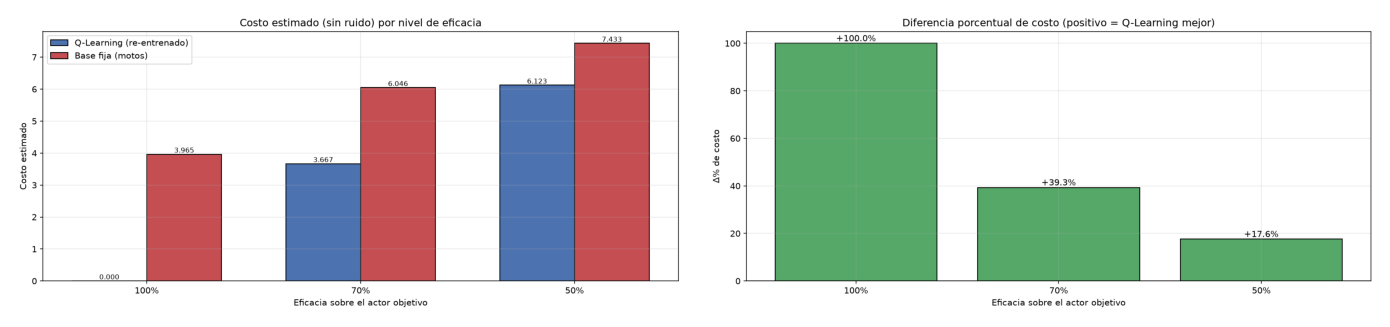

In [53]:
# Reproducir la figura comparativa final directamente (sin rehacer análisis)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, arch in zip(axes, ["g8_eval_sensibilidad.png", "g9_eval_diferencia.png"]):
    ruta = os.path.join(DIR_GRAFICAS, arch)
    if os.path.exists(ruta):
        img = mpimg.imread(ruta)
        ax.imshow(img)
        ax.axis("off")
    else:
        ax.set_title(f"No existe {arch}")
plt.tight_layout()
plt.show()


## 11.4 Interpretación general

1. **El problema se modeló de forma trazable.** El dataset se limpió y preparó (51,233 filas),
   y sobre sus frecuencias reales se construyó un entorno simulado: las tasas de víctimas por
   franja horaria y las distribuciones del estado provienen de los datos, y los únicos supuestos
   no empíricos son la matriz `EFICACIA` y los `PESOS`.

2. **El agente Q-Learning aprendió una política coherente con el entorno.** Asigna, por estado,
   la acción que mitiga al actor víctima del evento (automóvil → control de vehículos; moto →
   control de motos; peatón → protección; ciclista → infraestructura). Su recompensa media final
   es estable (convergencia del entrenamiento), lo que se verifica en la curva de aprendizaje.

3. **La política aprendida supera a una base fija en los tres niveles de eficacia evaluados**
   (100 %, 70 %, 50 %), pero la **magnitud de la ventaja depende del supuesto de eficacia**
   (ver tabla siguiente, generada directamente desde los resultados computados).


In [54]:
# Tabla dinámica de resultados de la sensibilidad (valores reales computados)
tabla_res = pd.DataFrame({
    "Eficacia": ["100 %", "70 %", "50 %"],
    "Costo Q-Learning": [resultados["100%"]["costo_ql"],
                          resultados["70%"]["costo_ql"],
                          resultados["50%"]["costo_ql"]],
    "Costo base fija": [resultados["100%"]["costo_base"],
                        resultados["70%"]["costo_base"],
                        resultados["50%"]["costo_base"]],
    "Ventaja (Δ%)": [resultados["100%"]["diff"],
                     resultados["70%"]["diff"],
                     resultados["50%"]["diff"]],
})
display(tabla_res.round(4))
print("La ventaja decrece al reducir la eficacia; el resultado es sensible al supuesto de mitigación.")

,Eficacia,Costo Q-Learning,Costo base fija,Ventaja (Δ%)
0,100 %,-0.0000,3.9646,100.000
1,70 %,3.6670,6.0458,39.346
2,50 %,6.1235,7.4332,17.620


La ventaja decrece al reducir la eficacia; el resultado es sensible al supuesto de mitigación.


## 11.5 Conclusiones

- Se consolidó un flujo completo: **EDA y limpieza → diseño del entorno y agente → evaluación
  y análisis de sensibilidad**.
- **Q-Learning permitió aprender, en el entorno simulado, una política interpretable** que
  supera a una estrategia de intervención fija bajo los supuestos del modelo. No se afirma que
  se trate de una política óptima absoluta ni que reduzca accidentes reales.
- El análisis de **sensibilidad** (100 % / 70 % / 50 % de eficacia) muestra que la ventaja es
  **robusta en dirección pero no en magnitud**: siempre favorece a Q-Learning, pero el
  beneficio se reduce cuanto menor es la eficacia asumida de las intervenciones.
- El carácter **tabular e interpretable** de Q-Learning permitió auditar el modelo y detectar
  y corregir incoherencias entre documentación y código (Sección 10).


## 11.6 Limitaciones

Los resultados corresponden a una **simulación** y **no demuestran reducciones reales de
accidentes**. En particular:

1. **Entorno simulado, sin transición causal real.** Las transiciones son independientes y
   simplificadas porque el dataset histórico **no contiene datos de transición entre estados
   consecutivos** ni efecto causal de las intervenciones.
2. **`EFICACIA` y `PESOS` no están estimados de datos.** Son supuestos de diseño; por eso la
   magnitud de la mejora no es transferible a la realidad (de ahí la prueba de sensibilidad).
3. **`tipo_dia` no modifica la recompensa** aunque forma parte del estado: es una simplificación
   de modelado pendiente de incorporar.
4. **Subregistro en los datos.** Las frecuencias de víctimas provienen de registros con flag,
   que sufren **subregistro** documentado en la Etapa 1 (`Tipo_Evento` sin dato ≈ 21 %, flags
   con `.` entre 75 % y 98 %). El "costo" subestima la siniestralidad real.
5. **Sin validación externa.** No se comparó con intervenciones reales ni contrafactuales de
   Cali; los resultados son una **propiedad del simulador**, no una predicción causal de
   reducción de accidentes.

